# EV Fleet Depot + Cattle Farms — Shared Battery Design and Dispatch

A single MILP that co-optimizes **what to build** (battery energy capacity,
inverter power, grid interconnection, charging plugs) and **how to run it**
(hourly charge / discharge / import), while serving three loads behind one
point of interconnection:

| Load | Character | Flexibility |
|---|---|---|
| **EV depot** | sharp opportunity-charging bursts | overnight fleet charging is a *window* |
| **Farm A** — dairy, ~1,200 cows | twice-daily milking spikes + weather-driven ventilation | parlour water heating |
| **Farm B** — beef + irrigation | feed handling + weather-driven ventilation | irrigation pumping |

Built in pure Pyomo — no energiapy components.

## Why put them behind one meter

Two *candidate* effects, which the diagnostic ladder in §7 measures separately
rather than assumes:

1. **Diversity.** If the farms and the depot peak at different times, the
   combined peak is less than the sum of the individual peaks, and the shared
   connection is cheaper than two separate ones before any battery is built.
   Whether that actually holds depends entirely on the timing — and in the data
   below it very nearly doesn't. See §7.
2. **Storage.** The battery shaves whatever combined peak remains. It now has
   three loads' worth of peak to work against, so it earns more than it would
   at the depot alone.

Keep them separate when you report results: sharing a meter is a *contract*,
sharing a battery is a *capital project*, and they are approved by different
people on different timescales.

## Formulation

**Sets** — $t \in T$ hours; $\ell \in L$ loads; $w \in W$ flexible energy
windows (each owned by one load).

**Design** — $E$ (MWh battery), $P^{ch}, P^{dis}$ (MW), $G$ (MW grid), $n$ (plugs).
**Operating** — $i_t$ import, $c_t$ charge, $d_t$ discharge, $s_t$ state of
charge, $q_{\ell t}$ power drawn by load $\ell$, $\hat{p}$ billing peak.

| | Constraint | Why it's here |
|---|---|---|
| **A** | $i_t + d_t = c_t + \sum_\ell q_{\ell t}$ | shared AC bus balance |
| **B** | $\eta_\ell q_{\ell t}\Delta t = \delta_{\ell t} + \sum_{w \in W_\ell} f_{wt}$ | delivery to each load |
| | $\delta_{\ell t} + u_{\ell t} = D_{\ell t}$ | inflexible demand |
| | $\sum_{t \in w} f_{wt} + u_w = E_w$ | flexible energy blocks |
| | $q_{ev,t} \le n\,\bar{p}$ | plug capacity |
| **C** | $s_t = (1-\sigma)s_{t-1} + \eta^{ch}c_t\Delta t - d_t\Delta t/\eta^{dis}$ | SOC balance, cyclic |
| | $\sigma^{min}E \le s_t \le \sigma^{max}E$ | usable depth of discharge |
| **D** | $c_t \le P^{ch}$, $d_t \le P^{dis}$ | power limits |
| | $P^{ch} \le C^{ch}E$, $P^{dis} \le C^{dis}E$ | **C-rate coupling** |
| **E** | $i_t \le G\,a_t$, $\hat{p} \ge i_t$ | interconnection + demand charge; $a_t \in \{0,1\}$ is grid availability |
| **F** | $\sum_{t: a_t = 1} d_t \Delta t \le N_{cyc}E$ | throughput / degradation (emergency cycling exempt) |
| | $c_t \le My_t$, $d_t \le M(1-y_t)$ | no simultaneous charge+discharge |
| **H** | $P^{dis} \ge \phi\,P^{isl}$, $(\sigma^{max}-\sigma^{min})E \ge \phi\,E^{isl}$ | **islanding spec** (design): enough power and usable energy to carry the site's inflexible load for `island_hours` |
| | $s_t \ge \sigma^{min}E + a_t\,\kappa\,r_t\,E^{isl}$ | **storm readiness** (operation): hold an absolute reserve scaled by weather-derived risk $r_t$ |

**Objective** — minimize annualized capex + energy + demand charge +
degradation + unserved-demand penalty. Unserved energy during an outage is
weighted by expected storms per year rather than by the 52-week scale.

In [36]:
from dataclasses import dataclass, field
from typing import List, Dict, Optional

import numpy as np
import pandas as pd
import pyomo.environ as pyo
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Configuration

Units are **MW / MWh / $ / hours** throughout. The `include_*` / `fix_*` flags
at the bottom drive the diagnostic ladder in §7.

In [37]:
def crf(rate: float, life: int) -> float:
    """Capital recovery factor — annualizes a lump-sum capex."""
    return rate * (1 + rate) ** life / ((1 + rate) ** life - 1)


@dataclass
class Config:
    # --- horizon ---------------------------------------------------------
    dt: float = 1.0                 # h per period
    hours_per_year: float = 8760.0

    # --- battery ---------------------------------------------------------
    eta_ch: float = 0.95            # charge efficiency
    eta_dis: float = 0.95           # discharge efficiency (round trip = product)
    sigma: float = 0.0              # self-discharge per period [fraction]
    soc_min: float = 0.10           # usable depth of discharge
    soc_max: float = 0.95
    crate_ch: float = 0.5           # MW of charge power per MWh installed
    crate_dis: float = 1.0          # MW of discharge power per MWh installed
    cap_e_max: float = 50.0         # MWh upper bound (also the big-M source)
    cycles_per_year: float = 400.0  # equivalent full cycles allowed

    capex_e: float = 250_000.0      # $/MWh of energy capacity
    capex_p: float = 90_000.0       # $/MW of power capacity (inverter)
    life_batt: int = 15
    c_deg: float = 4.0              # $/MWh of discharged throughput

    # --- chargers (EVSE) -------------------------------------------------
    eta_evse: float = 0.94
    p_plug: float = 0.150           # MW per plug (150 kW DC fast charger)
    capex_plug: float = 95_000.0    # $ per plug installed
    n_plugs_max: int = 60
    life_evse: int = 12

    # --- farm feeders ----------------------------------------------------
    eta_line: float = 0.97          # distribution loss to the farms
    capex_feeder: float = 60_000.0  # $/MW of farm feeder capacity
    life_feeder: int = 30

    # --- grid connection -------------------------------------------------
    cap_grid_max: float = 20.0      # MW
    capex_grid: float = 180_000.0   # $/MW of interconnection
    life_grid: int = 25
    c_demand: float = 15_000.0      # $/MW-month demand charge

    # --- financial -------------------------------------------------------
    discount_rate: float = 0.08
    rho_unmet: float = 50_000.0     # $/MWh penalty on undelivered energy

    # --- storms / resilience (see §9) ------------------------------------
    island_hours: float = 5.0       # design target: carry inflexible load this long
    island_frac: float = 0.0        # phi: fraction of the islanding spec built
    reserve_frac: float = 0.0       # kappa: readiness rule strength, 0 = weather-blind
    storms_per_year: float = 6.0    # weight on energy shed during an outage

    # --- model options (drive the diagnostic ladder in §7) ---------------
    include_ev: bool = True
    include_farms: bool = True
    include_battery: bool = True
    fix_cap_e: Optional[float] = None    # MWh; None = let the model size it
    include_demand_charge: bool = True
    include_cycle_limit: bool = True
    no_simultaneous: bool = False        # adds |T| binaries — see §7
    integer_plugs: bool = True

## 2. Data

### Three categories of demand, and the distinction matters

- **Inflexible** (`Load.fixed`) — must be delivered in *that* hour. Milking,
  feed handling, opportunity charging between routes. Short and sharp, so it
  sets the peak.
- **Flexible** (`windows`) — a block of energy that must land somewhere inside
  a window, timing free. Overnight fleet charging, parlour water heating,
  irrigation pumping. This is a *decision*, not a profile.
- **Volatile** — weather-driven ventilation. Not separately typed; it rides on
  `fixed`, but it's generated from a temperature series so that the two farms
  and the price all move together, the way they actually do in Texas.

That last coupling is the point. A hot afternoon raises farm ventilation load
on **both** farms at once *and* raises the ERCOT price *and* lands near the
depot's midday charging burst. Independent random noise on each load would
quietly average out and understate the peak the battery has to cover.

In [38]:
@dataclass
class Load:
    """One electrical load behind the shared meter."""
    name: str
    fixed: np.ndarray          # MWh that must be delivered in that hour
    eta: float = 1.0           # delivery efficiency (EVSE or farm feeder)
    kind: str = "farm"         # "ev" | "farm"


@dataclass
class SystemData:
    price: np.ndarray                  # $/MWh
    temperature: np.ndarray            # degC, drives ventilation + price
    loads: List[Load]
    windows: List[Dict]                # {name, owner, hours, energy}
    weather: pd.DataFrame              # pressure [hPa], humidity [%], wind [m/s]
    storm_risk: np.ndarray             # [0,1] — what the battery "sees"
    grid_up: np.ndarray                # 1 = grid available, 0 = outage
    label: str = "synthetic"

    @property
    def H(self) -> int:
        return len(self.price)

    def load(self, name: str) -> Load:
        return next(l for l in self.loads if l.name == name)


def storm_risk_index(weather: pd.DataFrame) -> np.ndarray:
    """Map raw weather to a [0,1] storm-risk signal.

    A hand-built logistic on the classic convective precursors: falling
    pressure (leads by hours), rising humidity, rising wind. This is the one
    function you'd replace with a classifier trained on NWS storm reports —
    the optimizer only ever sees its output.
    """
    z = (0.45 * (1013.0 - weather["pressure"].to_numpy())
         + 0.07 * (weather["humidity"].to_numpy() - 60.0)
         + 0.20 * (weather["wind"].to_numpy() - 4.0)
         - 4.0)
    return 1.0 / (1.0 + np.exp(-z))


def synthetic_week(seed: int = 0, ev_pm_hour: int = 17,
                   storm: bool = False, grid_fails: bool = False,
                   storm_hour: int = 88, outage_hours: int = 5) -> SystemData:
    """One representative summer week. REPLACE with real data.

    ev_pm_hour:  hour of the depot's mid-shift return burst. Exposed because
                 *when* it lands relative to afternoon milking drives the whole
                 load-diversity result — see the sensitivity in §7.
    storm:       inject a thunderstorm signature into the weather (pressure
                 drop, humidity rise, wind gust, post-frontal cooling).
    grid_fails:  the storm actually trips the grid for `outage_hours` from
                 `storm_hour`. Keeping this separate from `storm` is what lets
                 §9 model an operator who sees the weather but not the outage.
    """
    rng = np.random.default_rng(seed)
    H = 168
    t = np.arange(H)
    hod = t % 24
    day = t // 24

    # --- weather: the common driver ---------------------------------------
    # Diurnal swing plus a multi-day heat wave — this is what makes the farm
    # loads volatile AND correlated with each other and with price.
    daily_mean = 27 + 4 * np.sin((day - 1) / 7 * 2 * np.pi) + rng.normal(0, 1.2, 7)[day]
    temperature = daily_mean + 7 * np.sin((hod - 9) / 24 * 2 * np.pi) \
        + rng.normal(0, 0.8, H)

    # Own RNG stream so adding weather columns doesn't reshuffle price/load noise.
    rng_w = np.random.default_rng(seed + 1000)
    pressure = 1013.0 + 1.5 * np.sin((hod - 10) / 24 * 2 * np.pi) + rng_w.normal(0, 0.6, H)
    humidity = 55.0 - 12.0 * np.sin((hod - 9) / 24 * 2 * np.pi) + rng_w.normal(0, 3.0, H)
    wind = 3.5 + 1.0 * np.sin((hod - 14) / 24 * 2 * np.pi) + np.abs(rng_w.normal(0, 0.8, H))

    if storm:
        lead = t - storm_hour                              # hours relative to onset
        # Pressure falls over ~12 h ahead of the front and recovers fast after it.
        pressure -= 14.0 * np.where(lead < 0, np.exp(-(lead / 8.0) ** 2),
                                    np.exp(-(lead / 4.0) ** 2))
        # Moisture surges in ahead of the storm.
        humidity += 30.0 * np.exp(-((lead + 2) / 6.0) ** 2)
        # Gust front arrives *with* the storm — a coincident, not leading, signal.
        wind += 9.0 * np.exp(-((lead - 1) / 2.0) ** 2)
        # Outflow drops the temperature behind the front, which eases ventilation.
        temperature -= 5.0 * np.where(lead > 0, np.exp(-((lead - 1) / 4.0) ** 2), 0.0)

    weather = pd.DataFrame({"pressure": pressure,
                            "humidity": np.clip(humidity, 20, 100),
                            "wind": wind})
    storm_risk = storm_risk_index(weather)

    grid_up = np.ones(H)
    if storm and grid_fails:
        grid_up[storm_hour:storm_hour + outage_hours] = 0.0

    cooling_need = np.clip(temperature - 24.0, 0, None) / 10.0    # 0..~1.3

    # --- price: diurnal shape + scarcity, pushed up by heat ---------------
    base = 28 + 18 * np.sin((hod - 9) / 24 * 2 * np.pi) ** 2
    base += 22 * np.exp(-((hod - 18) ** 2) / 6.0)          # evening ramp
    base *= np.where(day >= 5, 0.85, 1.0)                  # softer weekends
    price = base + 26 * cooling_need ** 2 + rng.normal(0, 4, H)
    spike_hours = rng.choice(np.where((hod >= 16) & (hod <= 20))[0], 3, replace=False)
    price[spike_hours] += rng.uniform(150, 400, 3)         # scarcity events
    price = np.clip(price, 5.0, None)

    # === EV depot =========================================================
    # Inflexible: short, sharp bursts between routes.
    ev_fixed = np.zeros(H)
    ev_fixed += np.where((hod >= 11) & (hod <= 13), 1.8, 0.0)   # midday swap
    ev_fixed += np.where(hod == ev_pm_hour, 2.4, 0.0)           # mid-shift return
    ev_fixed *= np.where(day >= 5, 0.25, 1.0)                   # quiet weekends
    ev_fixed *= rng.uniform(0.9, 1.1, H)

    # === Farm A: dairy, ~1,200 cows =======================================
    # Milking twice a day is the signature load: vacuum pumps, milk transfer,
    # plate coolers. Inflexible — the cows decide the schedule, not the price.
    milking = ((hod >= 4) & (hod <= 6)) | ((hod >= 15) & (hod <= 17))
    cooling_tail = ((hod >= 6) & (hod <= 8)) | ((hod >= 17) & (hod <= 19))
    farmA = np.full(H, 0.040)                                   # base/controls
    farmA += np.where(milking, 0.300, 0.0)                      # parlour
    farmA += np.where(cooling_tail, 0.175, 0.0)                 # bulk tank
    farmA += 0.250 * cooling_need                               # ventilation
    farmA *= rng.uniform(0.92, 1.08, H)

    # === Farm B: beef + irrigated feed ====================================
    # No milking, so flatter — but ventilation/misting and irrigation make it
    # the more weather-exposed of the two.
    feed = ((hod >= 6) & (hod <= 7)) | ((hod >= 14) & (hod <= 15))
    farmB = np.full(H, 0.030)
    farmB += np.where(feed, 0.120, 0.0)                         # mixers, augers
    farmB += 0.155 * cooling_need                               # fans + misters
    farmB *= rng.uniform(0.92, 1.08, H)

    loads = [
        Load("EV depot", ev_fixed, eta=0.94, kind="ev"),
        Load("Farm A (dairy)", farmA, eta=0.97, kind="farm"),
        Load("Farm B (beef)", farmB, eta=0.97, kind="farm"),
    ]

    # === Flexible energy blocks ===========================================
    windows = []
    for d in range(7):
        # Fleet: back by 18:00, out by 06:00.
        hrs = [h for h in range(d * 24 + 18, d * 24 + 30) if h < H]
        if len(hrs) >= 6:
            windows.append({"name": f"ev_night_{d}", "owner": "EV depot",
                            "hours": hrs, "energy": 9.0 if d < 5 else 4.0})
        # Farm A: parlour water heating, hot before each milking.
        for tag, end in (("am", 4), ("pm", 15)):
            hrs = [h for h in range(d * 24 + end - 6, d * 24 + end) if 0 <= h < H]
            if len(hrs) >= 4:
                windows.append({"name": f"A_water_{d}{tag}", "owner": "Farm A (dairy)",
                                "hours": hrs, "energy": 0.45})
        # Farm B: irrigation pumping — a big, genuinely flexible daily block.
        hrs = [h for h in range(d * 24, d * 24 + 24) if h < H]
        windows.append({"name": f"B_irrig_{d}", "owner": "Farm B (beef)",
                        "hours": hrs, "energy": 2.6})

    tag = " + storm" if storm else ""
    tag += " + outage" if (storm and grid_fails) else ""
    return SystemData(price=price, temperature=temperature, loads=loads,
                      windows=windows, weather=weather, storm_risk=storm_risk,
                      grid_up=grid_up, label=f"synthetic summer week{tag}")


data = synthetic_week()

print(f"{data.label}: {data.H} h, "
      f"temp {data.temperature.min():.0f}–{data.temperature.max():.0f} degC, "
      f"price ${data.price.mean():.1f}/MWh avg, ${data.price.max():.0f} max\n")
for l in data.loads:
    flex = sum(w["energy"] for w in data.windows if w["owner"] == l.name)
    print(f"  {l.name:<16} peak {l.fixed.max():.3f} MW   "
          f"inflexible {l.fixed.sum():6.1f} MWh   flexible {flex:5.1f} MWh")
print(f"\n  {'COINCIDENT peak':<16} {sum(l.fixed for l in data.loads).max():.3f} MW"
      f"   (sum of individual peaks: "
      f"{sum(l.fixed.max() for l in data.loads):.3f} MW)")

synthetic summer week: 168 h, temp 16–39 degC, price $53.5/MWh avg, $393 max

  EV depot         peak 2.564 MW   inflexible   43.9 MWh   flexible  53.0 MWh
  Farm A (dairy)   peak 0.836 MW   inflexible   45.1 MWh   flexible   6.3 MWh
  Farm B (beef)    peak 0.381 MW   inflexible   20.0 MWh   flexible  18.2 MWh

  COINCIDENT peak  3.616 MW   (sum of individual peaks: 3.780 MW)


## 3. The model

`build_model(cfg, data) -> ConcreteModel`. Section letters match the table at
the top. Three things worth pointing at:

- **Loads are a set**, not hard-coded. `cfg.include_ev` / `cfg.include_farms`
  select which ones are active, which is what lets the ladder in §7 solve the
  depot and the farms standalone with the *same* model.
- **Flexible energy is indexed by (window, hour)**, not by hour alone — an hour
  can sit inside an EV window and a farm window at the same time.
- **The C-rate constraints are scalar**, not time-indexed. They link two
  *design* variables, which is what makes this a sizing problem at all.

In [39]:
def build_model(cfg: Config, data: SystemData) -> pyo.ConcreteModel:
    m = pyo.ConcreteModel(name="Depot + farms: battery design and dispatch")
    H = data.H
    dt = cfg.dt
    scale = cfg.hours_per_year / (H * dt)          # horizon cost -> annual cost

    # ---- which loads are active in this run ------------------------------
    active = [l for l in data.loads
              if (l.kind == "ev" and cfg.include_ev)
              or (l.kind == "farm" and cfg.include_farms)]
    names = [l.name for l in active]
    L = {l.name: l for l in active}
    wins = [w for w in data.windows if w["owner"] in names]
    win = {w["name"]: w for w in wins}
    owns = {n: [w["name"] for w in wins if w["owner"] == n] for n in names}

    m.T = pyo.RangeSet(0, H - 1)
    m.L = pyo.Set(initialize=names)
    m.W = pyo.Set(initialize=[w["name"] for w in wins])
    m.WT = pyo.Set(dimen=2, initialize=[(w["name"], t)
                                        for w in wins for t in w["hours"]])

    # ---- design variables ------------------------------------------------
    m.cap_e = pyo.Var(bounds=(0, cfg.cap_e_max))                     # MWh
    m.cap_pch = pyo.Var(bounds=(0, cfg.crate_ch * cfg.cap_e_max))    # MW
    m.cap_pdis = pyo.Var(bounds=(0, cfg.crate_dis * cfg.cap_e_max))  # MW
    m.cap_grid = pyo.Var(bounds=(0, cfg.cap_grid_max))               # MW
    m.cap_feeder = pyo.Var(bounds=(0, cfg.cap_grid_max))             # MW to farms
    m.n_plugs = pyo.Var(
        bounds=(0, cfg.n_plugs_max),
        domain=pyo.NonNegativeIntegers if cfg.integer_plugs else pyo.NonNegativeReals,
    )

    # ---- operating variables ---------------------------------------------
    m.imp = pyo.Var(m.T, domain=pyo.NonNegativeReals)        # MW from grid
    m.pch = pyo.Var(m.T, domain=pyo.NonNegativeReals)        # MW into battery
    m.pdis = pyo.Var(m.T, domain=pyo.NonNegativeReals)       # MW out of battery
    m.soc = pyo.Var(m.T, domain=pyo.NonNegativeReals)        # MWh stored
    m.q = pyo.Var(m.L, m.T, domain=pyo.NonNegativeReals)     # MW drawn by load
    m.d_fix = pyo.Var(m.L, m.T, domain=pyo.NonNegativeReals)   # MWh delivered
    m.u_fix = pyo.Var(m.L, m.T, domain=pyo.NonNegativeReals)   # MWh unserved
    m.d_flex = pyo.Var(m.WT, domain=pyo.NonNegativeReals)      # MWh delivered
    m.u_flex = pyo.Var(m.W, domain=pyo.NonNegativeReals)       # MWh unserved
    m.peak = pyo.Var(domain=pyo.NonNegativeReals)             # MW billing peak

    # ======================================================================
    # (A) Shared AC bus balance
    # ======================================================================
    @m.Constraint(m.T)
    def bus_balance(m, t):
        return m.imp[t] + m.pdis[t] == m.pch[t] + sum(m.q[l, t] for l in m.L)

    # ======================================================================
    # (B) Delivery to each load
    # ======================================================================
    @m.Constraint(m.L, m.T)
    def load_delivery(m, l, t):
        flex = sum(m.d_flex[w, t] for w in owns[l] if (w, t) in m.WT)
        return m.q[l, t] * L[l].eta * dt == m.d_fix[l, t] + flex

    @m.Constraint(m.L, m.T)
    def fixed_demand(m, l, t):
        return m.d_fix[l, t] + m.u_fix[l, t] == float(L[l].fixed[t])

    @m.Constraint(m.W)
    def window_energy(m, w):
        return sum(m.d_flex[w, t] for t in win[w]["hours"]) + m.u_flex[w] \
            == win[w]["energy"]

    if cfg.include_ev:
        @m.Constraint(m.T)
        def plug_limit(m, t):
            return m.q["EV depot", t] <= m.n_plugs * cfg.p_plug
    else:
        m.n_plugs.fix(0)

    if cfg.include_farms:
        @m.Constraint(m.T)
        def feeder_limit(m, t):
            return sum(m.q[l, t] for l in m.L if L[l].kind == "farm") <= m.cap_feeder
    else:
        m.cap_feeder.fix(0)

    # ======================================================================
    # (C) Battery state of charge
    # ======================================================================
    @m.Constraint(m.T)
    def soc_balance(m, t):
        prev = t - 1 if t > 0 else H - 1          # cyclic closure
        return m.soc[t] == (1 - cfg.sigma) * m.soc[prev] \
            + cfg.eta_ch * m.pch[t] * dt \
            - m.pdis[t] * dt / cfg.eta_dis

    @m.Constraint(m.T)
    def soc_upper(m, t):
        return m.soc[t] <= cfg.soc_max * m.cap_e

    @m.Constraint(m.T)
    def soc_lower(m, t):
        return m.soc[t] >= cfg.soc_min * m.cap_e

    # ======================================================================
    # (D) Power limits and the energy <-> power (C-rate) coupling
    # ======================================================================
    @m.Constraint(m.T)
    def charge_limit(m, t):
        return m.pch[t] <= m.cap_pch

    @m.Constraint(m.T)
    def discharge_limit(m, t):
        return m.pdis[t] <= m.cap_pdis

    @m.Constraint()
    def crate_charge(m):
        return m.cap_pch <= cfg.crate_ch * m.cap_e

    @m.Constraint()
    def crate_discharge(m):
        return m.cap_pdis <= cfg.crate_dis * m.cap_e

    # ======================================================================
    # (E) Grid connection and billing peak
    # ======================================================================
    up = data.grid_up

    @m.Constraint(m.T)
    def grid_limit(m, t):
        return m.imp[t] <= m.cap_grid * float(up[t])     # outage -> no import

    @m.Constraint(m.T)
    def peak_def(m, t):
        return m.peak >= m.imp[t]

    # ======================================================================
    # (F) Optional / staged constraints
    # ======================================================================
    if cfg.include_cycle_limit:
        cycles_h = cfg.cycles_per_year * (H * dt) / cfg.hours_per_year

        @m.Constraint()
        def cycle_limit(m):
            # Emergency cycling during an outage does not count against the
            # routine warranty budget — you don't shed load to protect cells.
            return sum(m.pdis[t] * dt for t in m.T if up[t] > 0.5) \
                <= cycles_h * m.cap_e

    # ======================================================================
    # (H) Resilience. Two separate commitments, because they are made by
    # different people at different times:
    #   - the DESIGN commits power and usable energy to an islanding spec
    #     derived from the site's own inflexible load (not from any outage);
    #   - the OPERATION holds an absolute energy reserve scaled by the
    #     weather-derived risk, while the grid is up. Once the outage hits,
    #     the reserve is there to be *used*.
    # The reserve is in MWh, not a fraction of cap_e — a proportional rule
    # rewards oversizing energy just to buy headroom above the reserve.
    # ======================================================================
    bus_fixed = sum(l.fixed / l.eta for l in active)          # MW at the bus
    P_island = float(bus_fixed.max())
    E_island = cfg.island_hours * float(np.percentile(bus_fixed, 90))
    m.P_island, m.E_island = P_island, E_island                # for reporting

    if cfg.island_frac > 0:
        @m.Constraint()
        def island_power(m):
            return m.cap_pdis >= cfg.island_frac * P_island

        @m.Constraint()
        def island_energy(m):
            return (cfg.soc_max - cfg.soc_min) * m.cap_e >= cfg.island_frac * E_island

    if cfg.reserve_frac > 0:
        reserve = {t: float(up[t]) * cfg.reserve_frac * float(data.storm_risk[t]) * E_island
                   for t in m.T}

        @m.Constraint(m.T)
        def soc_reserve(m, t):
            return m.soc[t] >= cfg.soc_min * m.cap_e + reserve[t]

    if cfg.no_simultaneous:
        m.y = pyo.Var(m.T, domain=pyo.Binary)
        M_ch = cfg.crate_ch * cfg.cap_e_max
        M_dis = cfg.crate_dis * cfg.cap_e_max

        @m.Constraint(m.T)
        def excl_charge(m, t):
            return m.pch[t] <= M_ch * m.y[t]

        @m.Constraint(m.T)
        def excl_discharge(m, t):
            return m.pdis[t] <= M_dis * (1 - m.y[t])

    if not cfg.include_battery:
        m.cap_e.fix(0.0)
    elif cfg.fix_cap_e is not None:
        m.cap_e.fix(cfg.fix_cap_e)

    # ======================================================================
    # (G) Objective — annualized total cost
    # ======================================================================
    a_batt = crf(cfg.discount_rate, cfg.life_batt)
    a_evse = crf(cfg.discount_rate, cfg.life_evse)
    a_grid = crf(cfg.discount_rate, cfg.life_grid)
    a_feed = crf(cfg.discount_rate, cfg.life_feeder)

    m.capex_ann = pyo.Expression(expr=(
        a_batt * (cfg.capex_e * m.cap_e + cfg.capex_p * (m.cap_pch + m.cap_pdis))
        + a_evse * cfg.capex_plug * m.n_plugs
        + a_grid * cfg.capex_grid * m.cap_grid
        + a_feed * cfg.capex_feeder * m.cap_feeder
    ))
    m.energy_cost = pyo.Expression(
        expr=scale * sum(float(data.price[t]) * m.imp[t] * dt for t in m.T))
    m.demand_cost = pyo.Expression(
        expr=(12.0 * cfg.c_demand * m.peak) if cfg.include_demand_charge else 0.0)
    m.deg_cost = pyo.Expression(
        expr=scale * cfg.c_deg * sum(m.pdis[t] * dt for t in m.T))
    # Unserved energy in normal hours recurs every week of the year; unserved
    # energy *during an outage* recurs once per storm. Weighting them the same
    # would size the battery as if the grid failed 52 times a year.
    m.penalty = pyo.Expression(expr=cfg.rho_unmet * (
        scale * sum(m.u_fix[l, t] for l in m.L for t in m.T if up[t] > 0.5)
        + cfg.storms_per_year * sum(m.u_fix[l, t] for l in m.L for t in m.T if up[t] < 0.5)
        + scale * sum(m.u_flex[w] for w in m.W)))

    m.obj = pyo.Objective(
        expr=m.capex_ann + m.energy_cost + m.demand_cost + m.deg_cost + m.penalty,
        sense=pyo.minimize)

    return m

## 4. Solve and report

In [40]:
def solve(m, solver="gurobi", tee=False, mipgap=1e-4):
    opt = pyo.SolverFactory(solver)
    if "gurobi" in solver:
        opt.options["MIPGap"] = mipgap
    return opt.solve(m, tee=tee)


def schedule(m, data) -> pd.DataFrame:
    """Hourly results as a tidy frame."""
    v = pyo.value
    T = list(m.T)
    df = pd.DataFrame({
        "hour": T,
        "price": data.price,
        "temperature": data.temperature,
        "grid_up": data.grid_up,
        "storm_risk": data.storm_risk,
        "import": [v(m.imp[t]) for t in T],
        "charge": [v(m.pch[t]) for t in T],
        "discharge": [v(m.pdis[t]) for t in T],
        "soc": [v(m.soc[t]) for t in T],
        "unserved": [sum(v(m.u_fix[l, t]) for l in m.L) for t in T],
    })
    for l in m.L:
        df[l] = [v(m.q[l, t]) for t in T]
    df["total load"] = df[[l for l in m.L]].sum(axis=1)
    return df


def summary(m, data, cfg) -> pd.Series:
    """Design decisions and the annual cost breakdown."""
    v = pyo.value
    scale = cfg.hours_per_year / (data.H * cfg.dt)
    E = v(m.cap_e)
    thr = sum(v(m.pdis[t]) * cfg.dt for t in m.T)
    load_peak = max(sum(v(m.q[l, t]) for l in m.L) for t in m.T)
    return pd.Series({
        "battery energy [MWh]": E,
        "battery discharge power [MW]": v(m.cap_pdis),
        "duration [h]": E / v(m.cap_pdis) if v(m.cap_pdis) > 1e-6 else np.nan,
        "grid connection [MW]": v(m.cap_grid),
        "billing peak [MW]": v(m.peak),
        "coincident load peak [MW]": load_peak,
        "farm feeder [MW]": v(m.cap_feeder),
        "plugs [#]": v(m.n_plugs),
        "equiv. full cycles/yr": scale * thr / E if E > 1e-6 else 0.0,
        "unserved [MWh/yr]": (          # same weighting as the penalty term
            scale * sum(v(m.u_fix[l, t]) for l in m.L for t in m.T if data.grid_up[t] > 0.5)
            + cfg.storms_per_year * sum(v(m.u_fix[l, t]) for l in m.L for t in m.T
                                        if data.grid_up[t] < 0.5)
            + scale * sum(v(m.u_flex[w]) for w in m.W)),
        "capex annualized [$/yr]": v(m.capex_ann),
        "energy [$/yr]": v(m.energy_cost),
        "demand charge [$/yr]": v(m.demand_cost),
        "degradation [$/yr]": v(m.deg_cost),
        "unserved penalty [$/yr]": v(m.penalty),
        "TOTAL [$/yr]": v(m.obj),
    })

## 5. The loads, before any optimization

Worth looking at the demand picture on its own before solving anything — the
diversity between the three loads is visible by eye, and it's what the shared
connection monetizes.

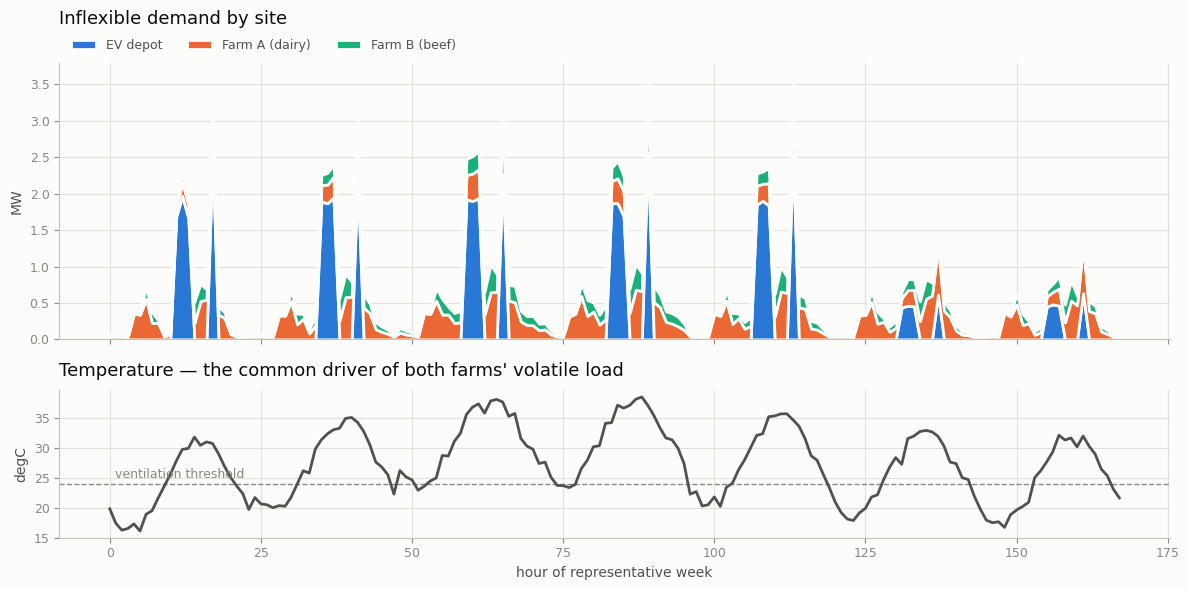

In [41]:
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # categorical slots 1-4


def _chrome(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(True, color=GRID, lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelsize=9)


def plot_loads(data, hours=None):
    """Inflexible demand by site, and the weather that drives its volatile part."""
    H = data.H if hours is None else hours
    x = np.arange(H)
    series = [l.fixed[:H] for l in data.loads]
    labels = [l.name for l in data.loads]

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                             height_ratios=[3, 1.6])
    fig.patch.set_facecolor(SURFACE)

    ax = axes[0]
    ax.stackplot(x, *series, colors=[S1, S2, S3], labels=labels,
                 edgecolor=SURFACE, linewidth=2, zorder=2)
    _chrome(ax)
    ax.set_ylabel("MW", color=INK2, fontsize=10)
    ax.set_title("Inflexible demand by site", color=INK, fontsize=13,
                 loc="left", pad=28)
    ax.legend(loc="lower left", ncol=3, frameon=False, fontsize=9,
              labelcolor=INK2, bbox_to_anchor=(0, 1.0))

    ax = axes[1]
    ax.plot(x, data.temperature[:H], color=INK2, lw=2, zorder=3)
    ax.axhline(24.0, color=MUTED, lw=1, ls="--", zorder=1)
    ax.annotate("ventilation threshold", xy=(x[0], 24.0), xytext=(4, 4),
                textcoords="offset points", fontsize=9, color=MUTED)
    _chrome(ax)
    ax.set_ylabel("degC", color=INK2, fontsize=10)
    ax.set_xlabel("hour of representative week", color=INK2, fontsize=10)
    ax.set_title("Temperature — the common driver of both farms' volatile load",
                 color=INK, fontsize=13, loc="left", pad=10)

    fig.tight_layout()
    return fig


plot_loads(data)
plt.show()

## 6. Dispatch plot

Four panels sharing one time axis rather than one panel with several y-scales —
MW, MWh, degC and $/MWh are not comparable, and overlaying them invites false
visual correlations.

In [42]:
def plot_dispatch(df, m, hours=None):
    d = df if hours is None else df.iloc[:hours]
    x = d["hour"].to_numpy()
    cap_e = pyo.value(m.cap_e)
    loads = [l for l in m.L]

    fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True,
                             height_ratios=[3, 2.4, 2, 2])
    fig.patch.set_facecolor(SURFACE)

    # --- panel 1: supply -------------------------------------------------
    ax = axes[0]
    ax.stackplot(x, d["import"], d["discharge"], colors=[S1, S3],
                 labels=["Grid import", "Battery discharge"],
                 edgecolor=SURFACE, linewidth=2, zorder=2)
    ax.fill_between(x, 0, -d["charge"], color=S2, label="Battery charge",
                    edgecolor=SURFACE, linewidth=2, zorder=2)
    ax.plot(x, d["total load"], color=INK, lw=2, label="Total site load", zorder=3)
    ax.axhline(0, color="#c3c2b7", lw=1, zorder=1)
    if pyo.value(m.peak) > 1e-6:
        ax.axhline(pyo.value(m.peak), color=MUTED, lw=1.5, ls="--", zorder=3)
        ax.annotate(f"billing peak {pyo.value(m.peak):.2f} MW",
                    xy=(x[-1], pyo.value(m.peak)), xytext=(-4, 5),
                    textcoords="offset points", ha="right", fontsize=9, color=INK2)
    _chrome(ax)
    ax.set_ylabel("MW", color=INK2, fontsize=10)
    ax.set_title("Supply: what the battery does to the grid draw",
                 color=INK, fontsize=13, loc="left", pad=28)
    ax.legend(loc="lower left", ncol=4, frameon=False, fontsize=9,
              labelcolor=INK2, bbox_to_anchor=(0, 1.0))

    # --- panel 2: demand by site -----------------------------------------
    ax = axes[1]
    ax.stackplot(x, *[d[l] for l in loads], colors=[S1, S2, S3][:len(loads)],
                 labels=loads, edgecolor=SURFACE, linewidth=2, zorder=2)
    _chrome(ax)
    ax.set_ylabel("MW", color=INK2, fontsize=10)
    ax.set_title("Demand: how it splits across the three sites",
                 color=INK, fontsize=13, loc="left", pad=28)
    ax.legend(loc="lower left", ncol=3, frameon=False, fontsize=9,
              labelcolor=INK2, bbox_to_anchor=(0, 1.0))

    # --- panel 3: state of charge ----------------------------------------
    ax = axes[2]
    ax.fill_between(x, d["soc"], color=S1, alpha=0.15, zorder=2)
    ax.plot(x, d["soc"], color=S1, lw=2, zorder=3)
    if cap_e > 1e-6:
        ax.axhline(cap_e, color=MUTED, lw=1.2, ls="--", zorder=1)
        for lvl in (0.95 * cap_e, 0.10 * cap_e):
            ax.axhline(lvl, color=MUTED, lw=1, ls=":", zorder=1)
        ax.annotate(f"{cap_e:.2f} MWh installed (dotted = usable SOC band)",
                    xy=(x[0], cap_e), xytext=(4, 5), textcoords="offset points",
                    fontsize=9, color=INK2)
    _chrome(ax)
    ax.set_ylabel("MWh", color=INK2, fontsize=10)
    ax.set_title("Battery state of charge", color=INK, fontsize=13,
                 loc="left", pad=10)

    # --- panel 4: price ---------------------------------------------------
    ax = axes[3]
    ax.plot(x, d["price"], color=INK2, lw=2, zorder=3)
    _chrome(ax)
    ax.set_ylabel("$/MWh", color=INK2, fontsize=10)
    ax.set_xlabel("hour of representative week", color=INK2, fontsize=10)
    ax.set_title("Energy price", color=INK, fontsize=13, loc="left", pad=10)

    fig.tight_layout()
    return fig

## 7. The diagnostic ladder

Each rung turns on exactly one mechanism, so any jump in cost is attributable.
Stages 1 and 2 solve the *same model* with only one site's loads active — that
gives an honest "what if they each built their own connection" reference.

| Stage | Sites | Battery | Purpose |
|---|---|---|---|
| 1 | depot only | – | standalone depot cost |
| 2 | farms only | – | standalone farms cost |
| 3 | all three | – | **diversity** value of one shared meter |
| 4 | all three | sized, LP | **storage** value on top of diversity |
| 5 | all three | sized, MILP | cost of modelling reality (integers, cycles) |

In [43]:
stages = {
    "1. depot alone, no battery":
        Config(include_farms=False, include_battery=False,
               integer_plugs=False, include_cycle_limit=False),
    "2. farms alone, no battery":
        Config(include_ev=False, include_battery=False,
               integer_plugs=False, include_cycle_limit=False),
    "3. combined, no battery":
        Config(include_battery=False, integer_plugs=False,
               include_cycle_limit=False),
    "4. combined + battery (LP)":
        Config(integer_plugs=False, include_cycle_limit=False),
    "5. full MILP":
        Config(integer_plugs=True, include_cycle_limit=True, no_simultaneous=True),
}

results, models = {}, {}
for name, cfg_i in stages.items():
    m_i = build_model(cfg_i, data)
    r = solve(m_i)
    assert str(r.solver.termination_condition) == "optimal", name
    results[name] = summary(m_i, data, cfg_i)
    models[name] = (m_i, cfg_i)
    print(f"{name:<28} solved")

comparison = pd.DataFrame(results)
comparison

1. depot alone, no battery   solved
2. farms alone, no battery   solved
3. combined, no battery      solved
4. combined + battery (LP)   solved
5. full MILP                 solved


,"1. depot alone, no battery","2. farms alone, no battery","3. combined, no battery",4. combined + battery (LP),5. full MILP
battery energy [MWh],0.000,0.000,0.000,3.978,3.978
battery discharge power [MW],0.000,0.000,0.000,2.215,2.215
duration [h],NaN,NaN,NaN,1.796,1.796
grid connection [MW],2.727,1.104,3.812,1.597,1.597
billing peak [MW],2.727,1.104,3.812,1.597,1.597
coincident load peak [MW],2.727,1.104,3.812,3.812,3.812
farm feeder [MW],0.000,1.104,1.104,1.104,1.104
plugs [#],18.183,0.000,18.183,18.183,19.000
equiv. full cycles/yr,0.000,0.000,0.000,395.863,395.863
unserved [MWh/yr],0.000,0.000,0.000,0.000,0.000


### Decomposing the value

Two separate effects, and it matters which is which — sharing a meter is a
contract, sharing a battery is a capital project.

In [44]:
S = {k: results[k]["TOTAL [$/yr]"] for k in results}
standalone = S["1. depot alone, no battery"] + S["2. farms alone, no battery"]

decomp = pd.Series({
    "depot standalone [$/yr]": S["1. depot alone, no battery"],
    "farms standalone [$/yr]": S["2. farms alone, no battery"],
    "sum if built separately [$/yr]": standalone,
    "combined, no battery [$/yr]": S["3. combined, no battery"],
    "  -> value of load diversity [$/yr]": standalone - S["3. combined, no battery"],
    "combined + battery [$/yr]": S["4. combined + battery (LP)"],
    "  -> value of the battery [$/yr]": S["3. combined, no battery"] - S["4. combined + battery (LP)"],
    "full MILP [$/yr]": S["5. full MILP"],
    "  -> cost of integer/cycle realism [$/yr]": S["5. full MILP"] - S["4. combined + battery (LP)"],
    "TOTAL saving vs separate builds [$/yr]": standalone - S["5. full MILP"],
    "  -> as % of separate builds": 100 * (standalone - S["5. full MILP"]) / standalone,
})
decomp.to_frame("value decomposition")

,value decomposition
depot standalone [$/yr],"1,043,999.346"
farms standalone [$/yr],"501,177.647"
sum if built separately [$/yr],"1,545,176.992"
"combined, no battery [$/yr]","1,541,307.969"
-> value of load diversity [$/yr],"3,869.023"
combined + battery [$/yr],"1,197,014.603"
-> value of the battery [$/yr],"344,293.366"
full MILP [$/yr],"1,207,317.199"
-> cost of integer/cycle realism [$/yr],"10,302.595"
TOTAL saving vs separate builds [$/yr],"337,859.794"


### Reading the decomposition

**Diversity is worth almost nothing here — about $3.9k/yr, 0.25%.** That is a
real result, not a modelling artifact: the depot's 17:00 mid-shift return lands
squarely on the dairy's afternoon milking and bulk-tank cooling, so the two
sites peak *together*. Sum of individual peaks 3.78 MW, coincident peak 3.62 MW.
Sharing a meter, by itself, buys you nearly nothing.

**The battery is worth ~$344k/yr**, cutting the billing peak from 3.81 MW to
1.60 MW. And it is worth that much *because* diversity failed — a badly-timed
pair of loads is exactly the condition that makes storage valuable. The two
effects are substitutes, not complements.

**Integer realism costs ~$10.3k/yr, and all of it is plug rounding**
(18.183 -> 19 plugs). The cycle limit lands at 395.9 of 400 allowed — just
barely slack — and the 168 no-simultaneous binaries change nothing at all,
because round-trip losses already made simultaneous charge/discharge
unprofitable. On a full 8760 run you can drop those binaries and verify the
condition afterwards with the sanity check in §8.

### Is coordination cheaper than steel?

If the loads peak together by accident of scheduling, the first question is
whether they have to. Moving the depot's afternoon return later is free;
a battery is not. This sweep rebuilds the data with the burst at different
hours and re-solves the no-battery combined case.

In [45]:
coord = {}
for h in range(17, 22):
    d_h = synthetic_week(ev_pm_hour=h)
    cfg_a = Config(include_farms=False, include_battery=False,
                   integer_plugs=False, include_cycle_limit=False)
    cfg_b = Config(include_ev=False, include_battery=False,
                   integer_plugs=False, include_cycle_limit=False)
    cfg_c = Config(include_battery=False, integer_plugs=False,
                   include_cycle_limit=False)
    tot = {}
    for tag, c in (("a", cfg_a), ("b", cfg_b), ("c", cfg_c)):
        mm = build_model(c, d_h)
        solve(mm)
        tot[tag] = summary(mm, d_h, c)
    coord[f"return at {h:02d}:00"] = pd.Series({
        "coincident load peak [MW]": tot["c"]["coincident load peak [MW]"],
        "combined cost, no battery [$/yr]": tot["c"]["TOTAL [$/yr]"],
        "value of diversity [$/yr]":
            tot["a"]["TOTAL [$/yr]"] + tot["b"]["TOTAL [$/yr]"] - tot["c"]["TOTAL [$/yr]"],
    })

pd.DataFrame(coord)

,return at 17:00,return at 18:00,return at 19:00,return at 20:00,return at 21:00
coincident load peak [MW],3.812,3.465,3.171,2.995,2.958
"combined cost, no battery [$/yr]","1,541,307.969","1,475,841.285","1,378,720.467","1,326,280.871","1,329,100.169"
value of diversity [$/yr],"3,869.023","65,349.571","117,302.792","136,857.286","179,674.127"


Moving the return from 17:00 to 20:00 drops the coincident peak from 3.81 MW
to 3.00 MW and takes **~$215k/yr off the no-battery combined cost** — roughly
60% of what the battery delivers, for no capital at all. If that reschedule is
operationally possible, it should be evaluated *before* the storage business
case, not after: it shrinks the peak the battery is sized against.

One caution on reading the table: **"value of diversity" is not the decision
metric.** It keeps climbing at 21:00 while combined cost ticks back *up*,
because the standalone depot baseline is moving too. Rank options on
`combined cost, no battery`, not on the diversity delta.

## 8. Dispatch of the full model

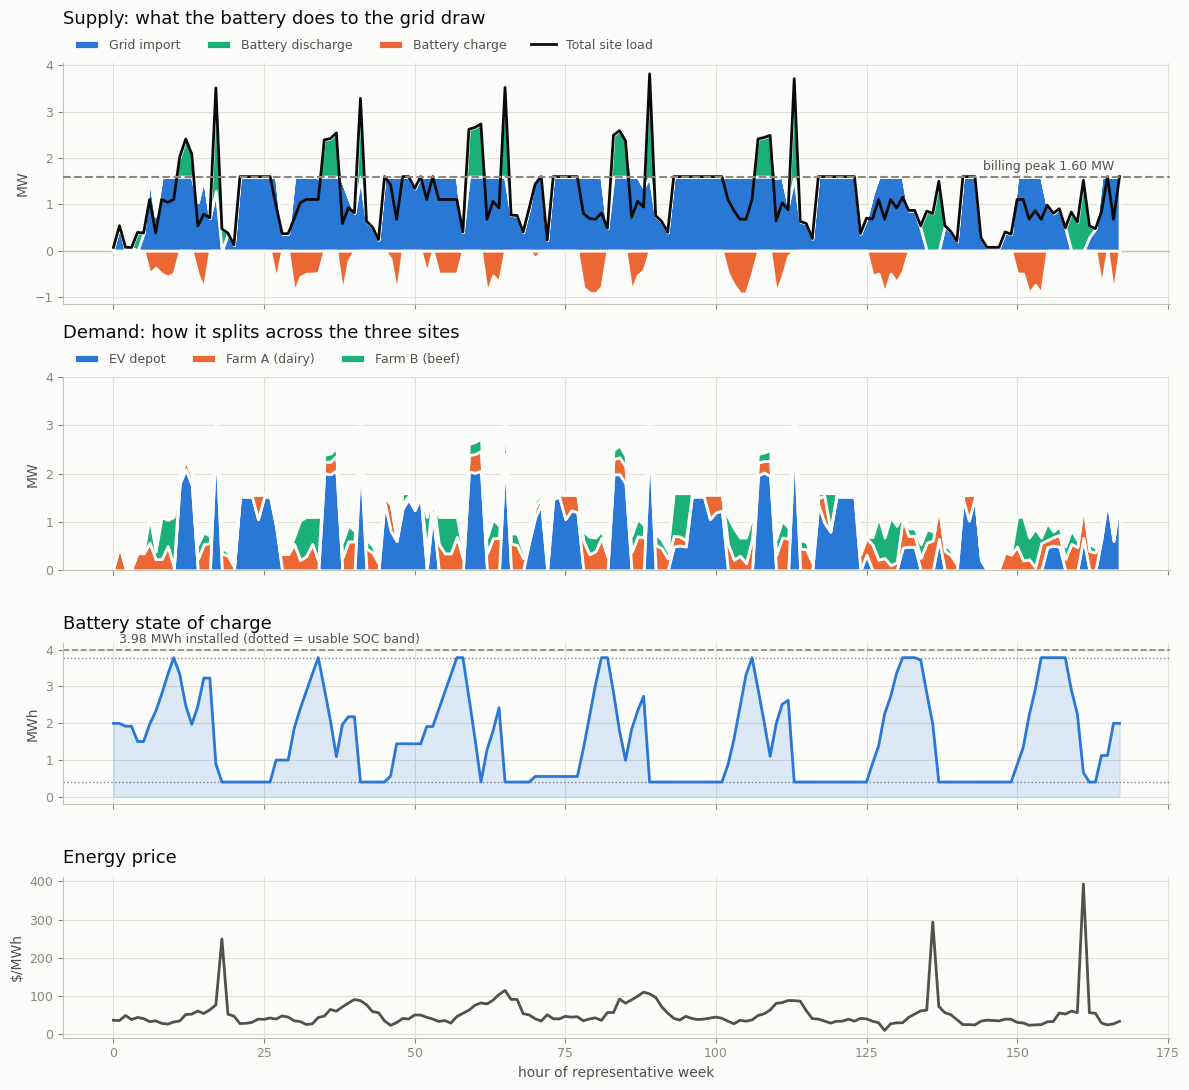

In [46]:
m, cfg = models["5. full MILP"]
df = schedule(m, data)
fig = plot_dispatch(df, m)
plt.show()

### Sanity checks

Run these every time you change the formulation. A model that solves is not a
model that is right.

In [53]:
v = pyo.value
loads = [l for l in m.L]
checks = {
    "no simultaneous charge+discharge":
        float(np.minimum(df["charge"], df["discharge"]).max()) < 1e-6,
    "SOC within usable band":
        bool((df["soc"] <= cfg.soc_max * v(m.cap_e) + 1e-6).all()
             and (df["soc"] >= cfg.soc_min * v(m.cap_e) - 1e-6).all()),
    "SOC balance closes cyclically at t=0":
        abs(v(m.soc[0]) - ((1 - cfg.sigma) * df["soc"].iloc[-1]
                           + cfg.eta_ch * df["charge"].iloc[0] * cfg.dt
                           - df["discharge"].iloc[0] * cfg.dt / cfg.eta_dis)) < 1e-6,
    "bus balance holds":
        float((df["import"] + df["discharge"] - df["charge"]
               - df["total load"]).abs().max()) < 1e-6,
    "all three loads present":
        len(loads) == 3,
    "all demand served":
        results["5. full MILP"]["unserved [MWh/yr]"] < 1e-6,
    "every flexible block delivered in its window":
        all(abs(sum(v(m.d_flex[w, t]) for t in
                    next(x for x in data.windows if x["name"] == w)["hours"])
                + v(m.u_flex[w])
                - next(x for x in data.windows if x["name"] == w)["energy"]) < 1e-6
            for w in m.W),
    "C-rate respected":
        v(m.cap_pdis) <= cfg.crate_dis * v(m.cap_e) + 1e-6,
    "cycles within limit":
        results["5. full MILP"]["equiv. full cycles/yr"] <= cfg.cycles_per_year + 1e-3,
}
for k, ok in checks.items():
    print(f"  {'PASS' if ok else 'FAIL'}  {k}")

  PASS  no simultaneous charge+discharge
  PASS  SOC within usable band
  PASS  SOC balance closes cyclically at t=0
  PASS  bus balance holds
  PASS  all three loads present
  PASS  all demand served
  PASS  every flexible block delivered in its window
  PASS  C-rate respected
  PASS  cycles within limit


## 9. Storms, outages, and what "seeing it coming" is worth

A thunderstorm trips the feeder and the whole site — depot and both farms —
is islanded on the battery for a few hours. The claim to test is that a
battery which watches the weather can charge *ahead* of the outage and carry
the loads through it.

### What the battery actually sees

An optimizer with the outage in its data has perfect foresight, which is not
the same thing as "seeing a pattern." So the information structure here is
explicit:

- **Weather** (pressure, humidity, wind) is observed. `storm_risk_index()`
  maps it to a risk signal $r_t \in [0,1]$ — a hand-built logistic on the
  classic convective precursors, with pressure leading the event by hours.
  That function is the one thing you'd swap for a real classifier.
- **The outage itself is not observed** until it happens. What the operator
  has instead is two commitments, constraint block **H**:
  - a **design** commitment $\phi$ = `island_frac`: build enough discharge
    power and usable energy to carry the site's inflexible load for
    `island_hours`. The spec ($P^{isl}$, $E^{isl}$) comes from the site's
    own load data, not from any particular storm.
  - an **operating** rule $\kappa$ = `reserve_frac`: while the grid is up,
    hold at least $\kappa\, r_t\, E^{isl}$ MWh in reserve. At $\kappa = 0$
    the battery is weather-blind.

Keeping those two apart is the point of the ladder. A resilience-sized
battery that ignores the weather is a common real-world configuration, and
the storm finds it wherever yesterday's peak shaving left it.

### The resilience ladder

Each rung is a two-phase simulation: **plan** on what the operator knows,
then **realize** the outage with the design and all pre-outage decisions
frozen, re-optimizing only from the moment the grid drops. (The realized
phase does know the outage *duration* once it starts — a small generosity to
the operator that a rolling-horizon version would remove.)

| Rung | Design $\phi$ | Readiness $\kappa$ | Outage? | Isolates |
|---|---|---|---|---|
| R0 | 0 | 0 | no | reference week |
| R1 | 0 | 0 | **yes** | cost of being blindsided |
| R2a | 1 | 0 | **yes** | value of *building* for islanding, weather-blind |
| R2 | 1 | 0.8 | **yes** | **value of the weather signal** on top of that |
| R3 | — | — (outage in data) | yes | value of perfect foresight (bound) |

R2a → R2 is the number that answers the question. R2 → R3 is how much a
better forecast could still be worth.

In [49]:
DESIGN_VARS = ["cap_e", "cap_pch", "cap_pdis", "cap_grid", "cap_feeder", "n_plugs"]


def realize(plan_m, cfg, data_true, t0):
    """Subject a plan to reality.

    Freeze the design and every operating decision before hour `t0` (the
    outage onset) at the planned values, then re-solve on `data_true` from
    `t0` onward. What the model *can't* undo is the point.
    """
    v = pyo.value
    m = build_model(cfg, data_true)
    for n in DESIGN_VARS:
        val = v(getattr(plan_m, n))
        getattr(m, n).fix(round(val) if n == "n_plugs" and cfg.integer_plugs else val)
    for t in range(t0):
        for n in ("imp", "pch", "pdis", "soc"):
            getattr(m, n)[t].fix(v(getattr(plan_m, n)[t]))
        for l in m.L:
            for n in ("q", "d_fix", "u_fix"):
                getattr(m, n)[l, t].fix(v(getattr(plan_m, n)[l, t]))
        if hasattr(m, "y"):
            m.y[t].fix(round(v(plan_m.y[t])))
    for (w, t) in m.WT:
        if t < t0:
            m.d_flex[w, t].fix(v(plan_m.d_flex[w, t]))
    r = solve(m)
    assert str(r.solver.termination_condition) == "optimal", "realize() infeasible"
    return m


def resilience(m, data, cfg) -> pd.Series:
    """Storm-week metrics on top of the usual summary."""
    v = pyo.value
    down = [t for t in m.T if data.grid_up[t] < 0.5]
    shed = sum(v(m.u_fix[l, t]) for l in m.L for t in down)
    served = sum(v(m.d_fix[l, t]) for l in m.L for t in down)
    t0 = down[0] if down else None
    s = summary(m, data, cfg)
    s["outage hours"] = len(down)
    s["SOC at outage onset [MWh]"] = v(m.soc[t0 - 1]) if t0 else np.nan
    s["SOC at onset [% usable]"] = (
        100 * (v(m.soc[t0 - 1]) - cfg.soc_min * v(m.cap_e))
        / ((cfg.soc_max - cfg.soc_min) * v(m.cap_e))
        if t0 and v(m.cap_e) > 1e-6 else np.nan)
    s["energy shed in outage [MWh]"] = shed
    s["outage load served [%]"] = 100 * served / (served + shed) if down else np.nan
    s["outage hours fully served"] = sum(
        1 for t in down if sum(v(m.u_fix[l, t]) for l in m.L) < 1e-6)
    return s


STORM_HOUR, OUTAGE_H = 88, 5          # Thursday 16:00, five hours
data_plan = synthetic_week(storm=True, grid_fails=False)
data_true = synthetic_week(storm=True, grid_fails=True,
                           storm_hour=STORM_HOUR, outage_hours=OUTAGE_H)

base = dict(integer_plugs=True, include_cycle_limit=True, no_simultaneous=False)
cfg_blind = Config(island_frac=0.0, reserve_frac=0.0, **base)
cfg_built = Config(island_frac=1.0, reserve_frac=0.0, **base)   # sized, weather-blind
cfg_aware = Config(island_frac=1.0, reserve_frac=0.8, **base)   # sized + readiness rule

# R0 / R1 share a plan: the operator ignores both the weather and the risk.
m_R0 = build_model(cfg_blind, data_plan); solve(m_R0)
m_R1 = realize(m_R0, cfg_blind, data_true, STORM_HOUR)
# R2a: built to island, but operated on price alone.
m_R2a_plan = build_model(cfg_built, data_plan); solve(m_R2a_plan)
m_R2a = realize(m_R2a_plan, cfg_built, data_true, STORM_HOUR)
# R2: built to island AND holds reserve when the weather says so.
m_R2_plan = build_model(cfg_aware, data_plan); solve(m_R2_plan)
m_R2 = realize(m_R2_plan, cfg_aware, data_true, STORM_HOUR)
# R3: the outage is in the data. Upper bound on what any forecast can achieve.
m_R3 = build_model(cfg_blind, data_true); solve(m_R3)

print(f"islanding spec from load data: P_island = {m_R2_plan.P_island:.2f} MW, "
      f"E_island = {m_R2_plan.E_island:.2f} MWh ({cfg_aware.island_hours:.0f} h)")

storm_ladder = pd.DataFrame({
    "R0 reference": resilience(m_R0, data_plan, cfg_blind),
    "R1 blindsided": resilience(m_R1, data_true, cfg_blind),
    "R2a sized, blind": resilience(m_R2a, data_true, cfg_built),
    "R2 sized + aware": resilience(m_R2, data_true, cfg_aware),
    "R3 foresight": resilience(m_R3, data_true, cfg_blind),
})
storm_ladder

islanding spec from load data: P_island = 3.71 MW, E_island = 11.86 MWh (5 h)


,R0 reference,R1 blindsided,"R2a sized, blind",R2 sized + aware,R3 foresight
battery energy [MWh],3.978,3.978,13.956,13.956,7.983
battery discharge power [MW],2.111,2.111,3.708,3.708,3.611
duration [h],1.884,1.884,3.764,3.764,2.211
grid connection [MW],1.597,1.597,1.362,1.654,1.762
billing peak [MW],1.597,1.597,1.362,1.654,1.762
coincident load peak [MW],3.708,3.708,3.708,3.708,3.708
farm feeder [MW],1.104,1.104,1.104,1.104,1.104
plugs [#],19.000,19.000,19.000,19.000,19.000
equiv. full cycles/yr,391.865,389.469,145.429,188.514,300.512
unserved [MWh/yr],0.000,22.933,27.765,0.000,0.000


In [50]:
C = {k: storm_ladder[k]["TOTAL [$/yr]"] for k in storm_ladder}
shed = {k: storm_ladder[k]["energy shed in outage [MWh]"] for k in storm_ladder}
pd.Series({
    "cost of being blindsided (R1 - R0) [$/yr]": C["R1 blindsided"] - C["R0 reference"],
    "value of building for islanding (R1 - R2a) [$/yr]": C["R1 blindsided"] - C["R2a sized, blind"],
    "value of the weather signal (R2a - R2) [$/yr]": C["R2a sized, blind"] - C["R2 sized + aware"],
    "remaining value of perfect foresight (R2 - R3) [$/yr]": C["R2 sized + aware"] - C["R3 foresight"],
    "premium if NO storm hits: sized only (R2a plan - R0) [$/yr]":
        pyo.value(m_R2a_plan.obj) - pyo.value(m_R0.obj),
    "premium if NO storm hits: sized + aware (R2 plan - R0) [$/yr]":
        pyo.value(m_R2_plan.obj) - pyo.value(m_R0.obj),
    "energy shed: R1 -> R2a -> R2 -> R3 [MWh]":
        " -> ".join(f"{shed[k]:.2f}" for k in
                    ("R1 blindsided", "R2a sized, blind", "R2 sized + aware", "R3 foresight")),
}).to_frame("resilience decomposition")

,resilience decomposition
cost of being blindsided (R1 - R0) [$/yr],"1,129,387.215"
value of building for islanding (R1 - R2a) [$/yr],"-489,654.349"
value of the weather signal (R2a - R2) [$/yr],"1,343,564.094"
remaining value of perfect foresight (R2 - R3) [$/yr],"149,588.524"
premium if NO storm hits: sized only (R2a plan - R0) [$/yr],"246,913.308"
premium if NO storm hits: sized + aware (R2 plan - R0) [$/yr],"281,582.186"
energy shed: R1 -> R2a -> R2 -> R3 [MWh],3.82 -> 4.63 -> 0.00 -> 0.00


### Reading the ladder

**R1 — blindsided.** The peak-shaving battery (4.0 MWh) is at 57% usable SOC
when the grid drops at 16:00, because it has just covered the midday burst.
It carries the site for one hour and sheds 3.8 of 5.6 MWh. At $50k/MWh and
six storms a year, that is $1.1M/yr of lost load.

**R2a — built to island, operated blind.** This is the rung that surprised
me. The 14 MWh battery does *worse* than R1: 17% served, 4.6 MWh shed,
30% SOC at onset. A bigger battery shaves harder and arbitrages deeper into
the afternoon price rise, so by 16:00 it is *emptier* than the small one.
Sizing for resilience without a readiness rule buys the capex and keeps the
outage exposure — it is strictly the worst configuration on the table.

**R2 — built to island, watches the weather.** Same hardware as R2a. The
readiness rule pulls SOC to 90% by onset; the site rides through all five
hours with zero shed. The rule costs ~$35k/yr on top of the sizing premium
in a week where nothing happens, and is worth ~$1.35M/yr in the week
something does. **R2a → R2 is the value of seeing it coming.**

**R3 — perfect foresight.** Also 100% served, but with an 8 MWh battery,
not 14. The islanding spec here is `island_hours` x the 90th-percentile bus
load, which is conservative — the p90 is set by the depot's midday bursts,
not by what an afternoon outage actually needs. Most of the R2 → R3 gap
($150k/yr) is that over-build, not forecast quality. If you want a tighter
spec, derive $E^{isl}$ from the worst `island_hours`-long rolling window of
load rather than the p90.

### The storm, hour by hour

Zoomed to the two days around the event. The top panel is what the battery
sees; the shaded band is what actually happens. Compare the three SOC traces
going *into* the band — that is the entire phenomenon.

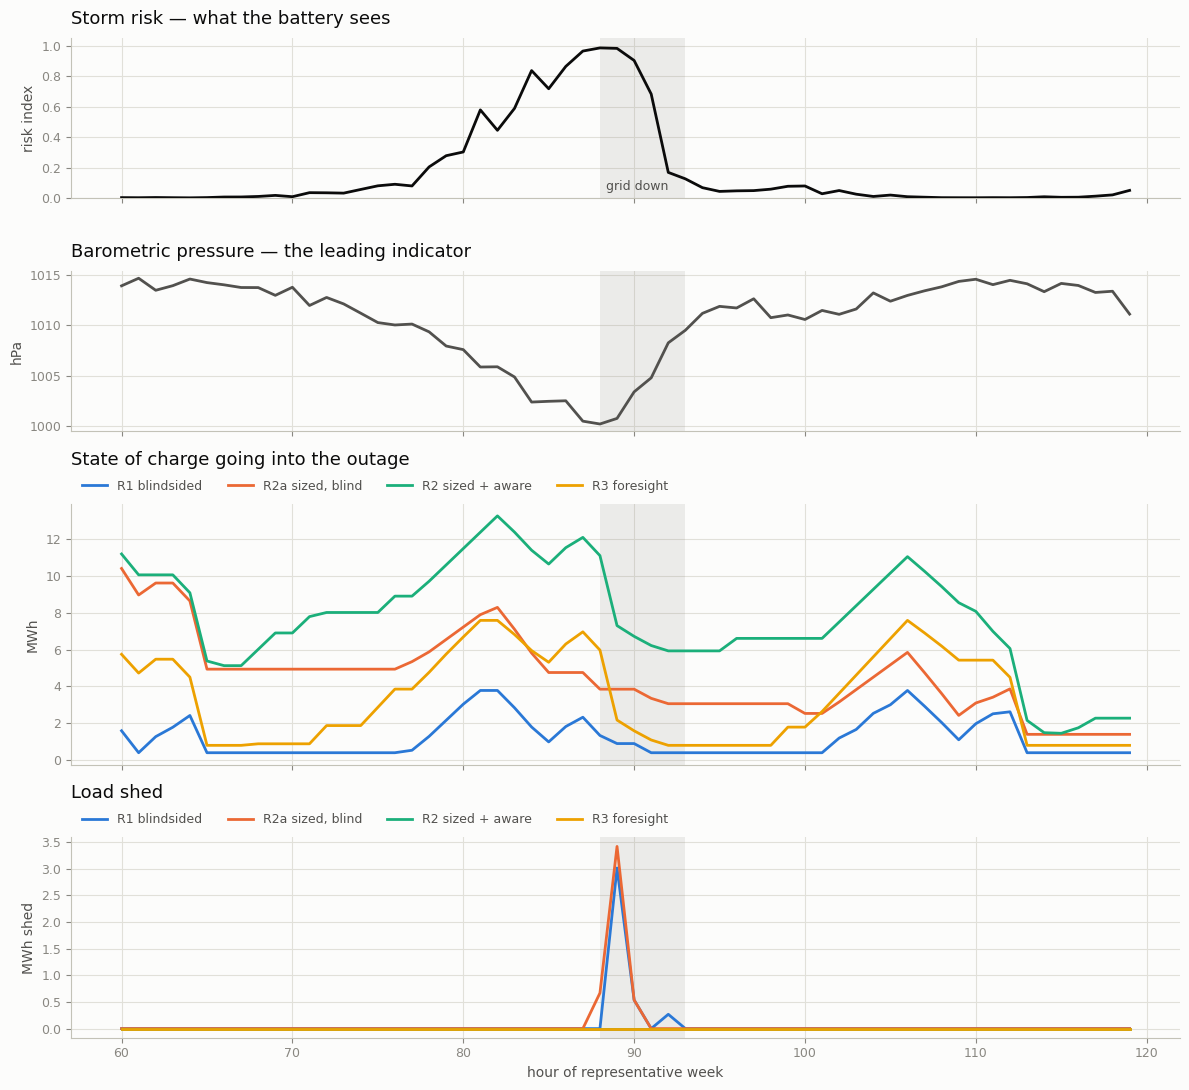

In [51]:
def plot_storm(data_true, cases: Dict[str, pd.DataFrame], window=(60, 120)):
    a, b = window
    x = np.arange(a, b)
    w = data_true.weather.iloc[a:b]
    down = np.where(data_true.grid_up[a:b] < 0.5)[0]
    t_on, t_off = (x[down[0]], x[down[-1]] + 1) if len(down) else (None, None)

    def shade(ax):
        if t_on is not None:
            ax.axvspan(t_on, t_off, color=MUTED, alpha=0.14, lw=0, zorder=1)

    fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True,
                             height_ratios=[1.6, 1.6, 2.6, 2])
    fig.patch.set_facecolor(SURFACE)

    ax = axes[0]
    ax.plot(x, data_true.storm_risk[a:b], color=INK, lw=2, zorder=3)
    shade(ax); _chrome(ax)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("risk index", color=INK2, fontsize=10)
    ax.set_title("Storm risk — what the battery sees", color=INK, fontsize=13,
                 loc="left", pad=10)
    if t_on is not None:
        ax.annotate("grid down", xy=(t_on, 0.0), xytext=(4, 6),
                    textcoords="offset points", fontsize=9, color=INK2)

    ax = axes[1]
    ax.plot(x, w["pressure"], color=INK2, lw=2, zorder=3)
    shade(ax); _chrome(ax)
    ax.set_ylabel("hPa", color=INK2, fontsize=10)
    ax.set_title("Barometric pressure — the leading indicator", color=INK,
                 fontsize=13, loc="left", pad=10)

    ax = axes[2]
    for (name, df), col in zip(cases.items(), [S1, S2, S3, S4]):
        ax.plot(x, df["soc"].iloc[a:b], color=col, lw=2, label=name, zorder=3)
    shade(ax); _chrome(ax)
    ax.set_ylabel("MWh", color=INK2, fontsize=10)
    ax.set_title("State of charge going into the outage", color=INK,
                 fontsize=13, loc="left", pad=28)
    ax.legend(loc="lower left", ncol=4, frameon=False, fontsize=9,
              labelcolor=INK2, bbox_to_anchor=(0, 1.0))

    ax = axes[3]
    for (name, df), col in zip(cases.items(), [S1, S2, S3, S4]):
        ax.plot(x, df["unserved"].iloc[a:b], color=col, lw=2, label=name, zorder=3)
    shade(ax); _chrome(ax)
    ax.set_ylabel("MWh shed", color=INK2, fontsize=10)
    ax.set_xlabel("hour of representative week", color=INK2, fontsize=10)
    ax.set_title("Load shed", color=INK, fontsize=13, loc="left", pad=28)
    ax.legend(loc="lower left", ncol=4, frameon=False, fontsize=9,
              labelcolor=INK2, bbox_to_anchor=(0, 1.0))

    fig.tight_layout()
    return fig


plot_storm(data_true, {
    "R1 blindsided": schedule(m_R1, data_true),
    "R2a sized, blind": schedule(m_R2a, data_true),
    "R2 sized + aware": schedule(m_R2, data_true),
    "R3 foresight": schedule(m_R3, data_true),
})
plt.show()

### How hard should the battery lean on the forecast?

With the islanding spec built ($\phi = 1$), `reserve_frac` is the remaining
dial. Too low and the storm finds the battery half empty; too high and it
spends every high-risk afternoon sitting on charge it could have used for
peak shaving — and pays the demand charge for the privilege, since the risk
window lands right on the depot's afternoon burst. Both costs are on the
table below, including the premium paid in weeks where the storm never trips
the grid.

In [52]:
sweep = {}
for k in (0.0, 0.25, 0.5, 0.75, 0.9, 1.0):
    c = Config(island_frac=1.0, reserve_frac=k, **base)
    mp = build_model(c, data_plan); solve(mp)
    mr = realize(mp, c, data_true, STORM_HOUR)
    s = resilience(mr, data_true, c)
    sweep[f"kappa = {k:.2f}"] = pd.Series({
        "battery energy [MWh]": s["battery energy [MWh]"],
        "SOC at onset [% usable]": s["SOC at onset [% usable]"],
        "energy shed in outage [MWh]": s["energy shed in outage [MWh]"],
        "outage load served [%]": s["outage load served [%]"],
        "realized cost, storm hits [$/yr]": s["TOTAL [$/yr]"],
        "planned cost, no storm [$/yr]": pyo.value(mp.obj),
        "readiness premium [$/yr]": pyo.value(mp.obj) - pyo.value(m_R0.obj),
    })
pd.DataFrame(sweep)

,kappa = 0.00,kappa = 0.25,kappa = 0.50,kappa = 0.75,kappa = 0.90,kappa = 1.00
battery energy [MWh],13.956,13.956,13.956,13.956,14.648,16.018
SOC at onset [% usable],28.306,52.933,68.953,86.647,93.940,94.458
energy shed in outage [MWh],4.627,3.058,1.000,0.000,0.000,0.000
outage load served [%],17.343,45.374,82.132,100.000,100.000,100.000
"realized cost, storm hits [$/yr]","2,817,350.572","2,356,336.200","1,751,078.367","1,466,163.136","1,503,787.759","1,543,114.862"
"planned cost, no storm [$/yr]","1,445,222.316","1,446,687.763","1,450,066.489","1,469,294.831","1,511,677.422","1,551,177.699"
readiness premium [$/yr],"246,913.308","248,378.754","251,757.480","270,985.822","313,368.413","352,868.691"


Monotone, which is what a well-posed dial should be. Shed falls from 4.6 MWh
to zero by $\kappa = 0.75$, at a premium only ~$24k/yr above the pure sizing
cost. Above that the battery starts *growing* again (14.0 → 16.0 MWh at
$\kappa = 1$): the reserve now eats so much of the usable band during the
high-risk afternoon that the model buys extra energy purely for peak-shaving
headroom above it. That is the demand charge and the readiness rule fighting
over the same six hours — a real tension, and a reason to prefer a risk
signal with a sharper onset over a stricter $\kappa$.

### On the annualization

The representative week now contains a storm. Costs that recur weekly are
still scaled by 52; energy shed *during the outage* is scaled by
`storms_per_year` instead, so the battery isn't sized as if the grid failed
every Thursday. That is a pragmatic patch, not a proper expectation. The
honest version is two-stage stochastic — shared design, a calm-week scenario
and a storm-week scenario with their own weights — and the model's separation
of design from operating variables already makes that a mechanical change.

## 10. Where to take it next

**Swap in real data first.** Everything above is only as good as
`synthetic_week()`. You need ERCOT hourly prices for the node, depot
telematics, metered farm interval data (most co-ops will provide 15-min data
on request), and for §9, hourly surface observations plus a storm-report
archive to fit `storm_risk_index()` against.

Then, roughly in order of how much they change the answer:

1. **Real volatility, not a deterministic profile.** Farm ventilation, price,
   and storms are all genuinely stochastic. The natural next step is two-stage
   stochastic: design (`cap_e`, `cap_pdis`, `cap_grid`, `n_plugs`) in stage 1,
   dispatch per scenario in stage 2, over a set of weather/price/outage
   scenarios. The model's structure already separates those two variable
   groups, and it fixes the annualization caveat in §9 properly.
2. **Representative days with weights.** A full 8760 LP is fine; the MILP with
   binaries is not. Cluster to ~12 representative days and weight them in the
   objective — same approach as the AICHE work. Note the farm loads are
   strongly seasonal (ventilation, irrigation), so cluster on temperature as
   well as price.
3. **4CP.** In ERCOT the transmission charge keys off demand during four
   specific 15-min intervals in summer — exactly when farm ventilation peaks.
   That's a much more valuable and much more targeted objective than a monthly
   peak.
4. **Who pays?** The model minimizes *system* cost, but the depot and the two
   farms are separate businesses. Splitting the saving is a cost-allocation
   problem (Shapley value or nucleolus over the four coalitions) and the
   standalone stages 1 and 2 are exactly the standalone costs you need for it.
5. **On-site generation.** A farm with roof or land is a natural PV host, and
   PV pairs with both the ventilation load and the battery.
6. **Emissions.** Add grid carbon intensity and run an epsilon-constraint
   sweep for a cost/GWP Pareto front.